### Simple Linear regression

**1.1 Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**1.2 Load the dataset**

In [10]:
df = pd.read_csv("../data/Salary_dataset.csv", index_col=0)
df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


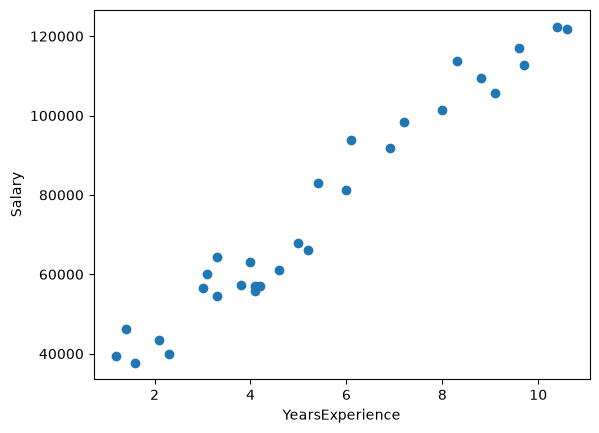

In [11]:
# Check realtion between feature and target
plt.scatter(df["YearsExperience"], df["Salary"])
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.show()

- Sort of linear realtion

**1.4 divide the data into independent and dependent features**

In [ ]:
X = df[["YearsExperience"]] 
y = df["Salary"]

**1.5 train test split**

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20,
                                                    random_state=42)
X_train.shape, X_test.shape

((24, 1), (6, 1))

**1.6 Standardization**

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**1.7 Train the model**

In [17]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[27151.54]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.421e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[4.9]


In [24]:
print("The slope or coefficient of weight is :", model.coef_[0])
print("Intercept : ", model.intercept_)

The slope or coefficient of weight is : 27151.537425833674
Intercept :  74208.625


**1.8 Visualize the line**

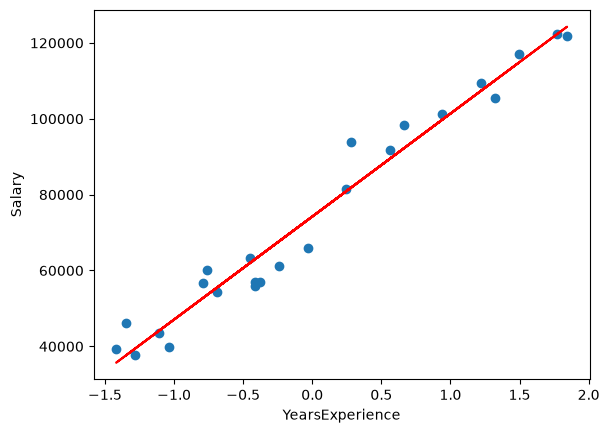

In [18]:
plt.scatter(X_train, y_train)
plt.plot(X_train, model.predict(X_train), c='r')
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.show()

**1.9 Predication on test data**

In [19]:
y_pred = model.predict(X_test)
y_pred

array([115791.21011287,  71499.27809463, 102597.86866063,  75268.80422384,
        55478.79204548,  60190.69970699])

In [21]:
y_test.values

array([112636.,  67939., 113813.,  83089.,  64446.,  57190.])

**1.10 Performance matrix**

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(mse)
print(mae)
print(rmse)

49830096.85590836
6286.453830757742
7059.043621901507


In [27]:
score = r2_score(y_test, y_pred)
score

0.9024461774180498

In [30]:
# Adjusted r sqaured
n = X_test.shape[0]
k = X_test.shape[1]

adjusted_rsquared = 1 - (1 - score)*(n -1) / (n - k -1)
adjusted_rsquared

0.8780577217725622

**1.11 Predication on new data**

In [35]:
x = 3
x_scaled = scaler.transform([[x]])
model.predict(x_scaled)

c:\Users\avina\anaconda3\envs\ml-learning\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([52651.64744857])

**1.11 Assumptions**

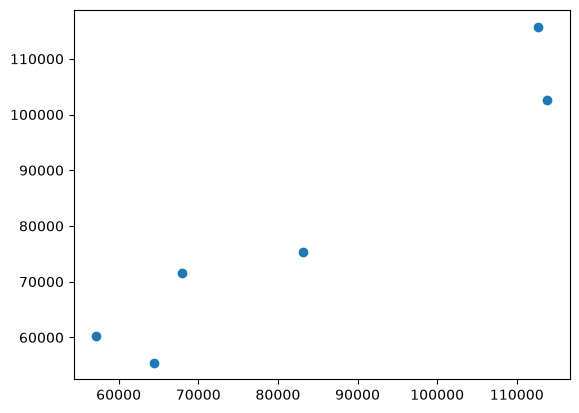

In [37]:
# Plot a scatter plot for the predicatin
plt.scatter(y_test, y_pred);

In [38]:
# Residuals
residuals = y_test - y_pred
residuals

27    -3155.210113
15    -3560.278095
23    11215.131339
17     7820.195776
8      8967.207955
9     -3000.699707
Name: Salary, dtype: float64

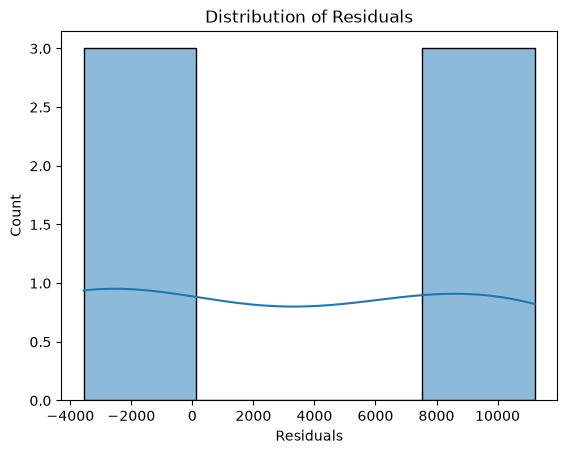

In [44]:
# plot the residuals 
sns.histplot(residuals, kde=True)
plt.xlabel("Residuals")
plt.title("Distribution of Residuals")
plt.show()

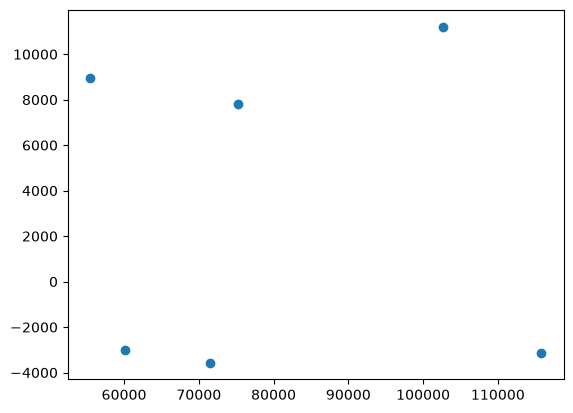

In [45]:
## scatter plot eith respect to predication and residuals
# uniform distribution
plt.scatter(y_pred, residuals)